In [1]:
from Bio import SeqIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re


In [ ]:
# 1. Load the genome sequence
genome_record = SeqIO.read("GCA_015565735.1_ASM1556573v1_genomic.fna", "fasta")
genome_seq = str(genome_record.seq)

# 2. Load the protein table
df = pd.read_excel("protein_table.xlsx")

# # 3. Filter for sense strand ('plus') and take the first 1000 genes
# df_plus = df[df['Orientation'] == 'plus'].copy()
# df_plus = df_plus.head(1000)

# 3. Filter for sense strand ('plus') AND ensure there is enough upstream space
df_plus = df[(df['Orientation'] == 'plus') & (df['Begin'] > 100)].copy()

# NOW take exactly the first 1000 valid genes
df_plus = df_plus.head(1000)
#print(df_plus)


sequences = []
start_codons = []

# 4. Extract 100 bases upstream + 3 bases downstream (the start codon itself)
for idx, row in df_plus.iterrows():
    begin = int(row['Begin'])
    
    # Skip genes too close to the start of the chromosome to avoid index errors
    if begin > 100:
        # Convert 1-based coordinate to 0-based Python index
        # Extract from 100 bases before the start, up to the end of the 3-base start codon
        start_idx = begin - 1
        seq = genome_seq[start_idx - 100 : start_idx + 3]
        
        sequences.append(seq)
        start_codons.append(seq[-3:]) # The last 3 bases should be the start codon

# Verify the code by checking the frequency of Methionine start codons
print("Verification - Start Codon Frequencies:")
print(pd.Series(start_codons).value_counts())



print("\nVerification - Individual Start Codons for the first 5 genes:")
print("-" * 60)

# Iterate through the first 5 genes in the filtered dataframe
for i in range(5):
    # Get the gene name and locus tag from the dataframe
    gene_name = df_plus.iloc[i]['Name']
    locus_tag = df_plus.iloc[i]['Locus tag']
    
    # Get the corresponding start codon (last 3 bases of the extracted sequence)
    start_codon = sequences[i][-3:]
    
    print(f"Locus: {locus_tag} | Codon: {start_codon} | Gene: {gene_name}")

Verification - Start Codon Frequencies:
ATG    861
GTG     80
TTG     19
GCA      6
TGT      4
GAA      3
GGT      3
CTG      3
GCG      2
AAA      2
GTC      2
CCT      2
GGG      2
CGG      1
GCT      1
TCT      1
GCC      1
CGC      1
ACA      1
CTC      1
ATA      1
ATC      1
CGT      1
TTA      1
Name: count, dtype: int64

Verification - Individual Start Codons for the first 5 genes:
------------------------------------------------------------
Locus: IT784_RS00010 | Codon: ATG | Gene: DNA polymerase III subunit beta
Locus: IT784_RS00015 | Codon: ATG | Gene: DNA replication/repair protein RecF
Locus: IT784_RS00020 | Codon: ATG | Gene: DNA topoisomerase (ATP-hydrolyzing) subunit B
Locus: IT784_RS00040 | Codon: ATG | Gene: sugar-phosphatase
Locus: IT784_RS00045 | Codon: ATG | Gene: hypothetical protein


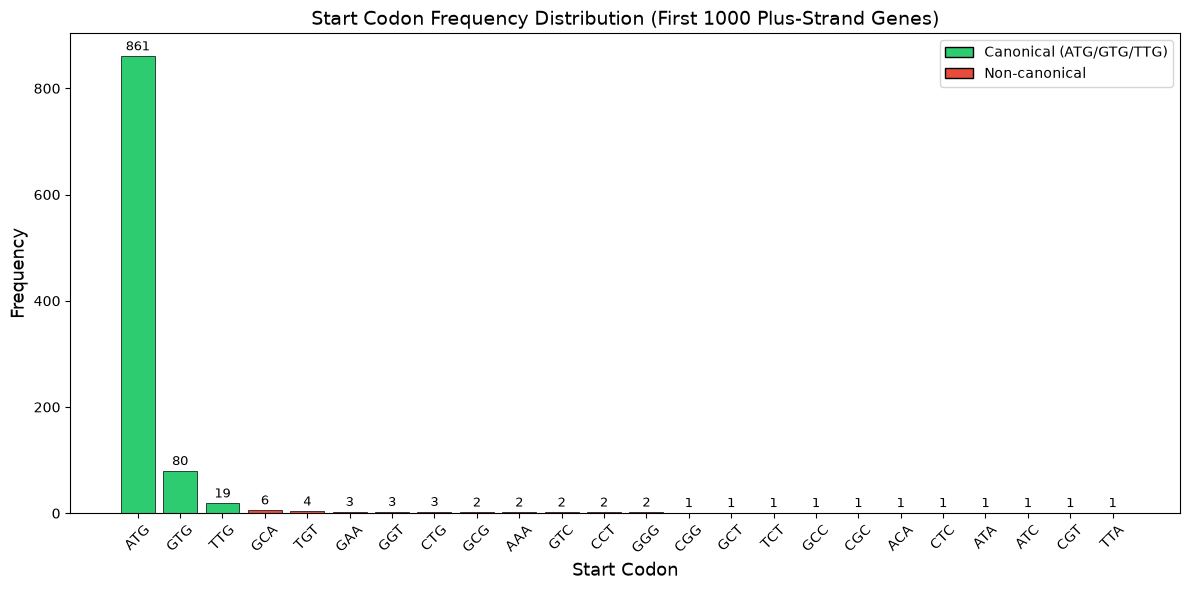

In [ ]:
codon_counts = pd.Series(start_codons).value_counts()

fig, ax = plt.subplots(figsize=(12, 6))

colors = ['#2ecc71' if c in ['ATG', 'GTG', 'TTG'] else '#e74c3c' for c in codon_counts.index]

ax.bar(codon_counts.index, codon_counts.values, color=colors, edgecolor='black', linewidth=0.5)

ax.set_xlabel('Start Codon', fontsize=13)
ax.set_ylabel('Frequency', fontsize=13)
ax.set_title('Start Codon Frequency Distribution (First 1000 Plus-Strand Genes)', fontsize=14)
ax.tick_params(axis='x', rotation=45)

# Annotate counts on top of each bar
for i, (codon, count) in enumerate(zip(codon_counts.index, codon_counts.values)):
    ax.text(i, count + 5, str(count), ha='center', va='bottom', fontsize=9)

ax.legend(
    handles=[
        plt.Rectangle((0,0),1,1, facecolor='#2ecc71', edgecolor='black', label='Canonical (ATG/GTG/TTG)'),
        plt.Rectangle((0,0),1,1, facecolor='#e74c3c', edgecolor='black', label='Non-canonical'),
    ],
    loc='upper right'
)

plt.tight_layout()
plt.show()


## Question 01

1. Percentage of genes with WWWW promoters: 982/1000 * 100 = 98.20%


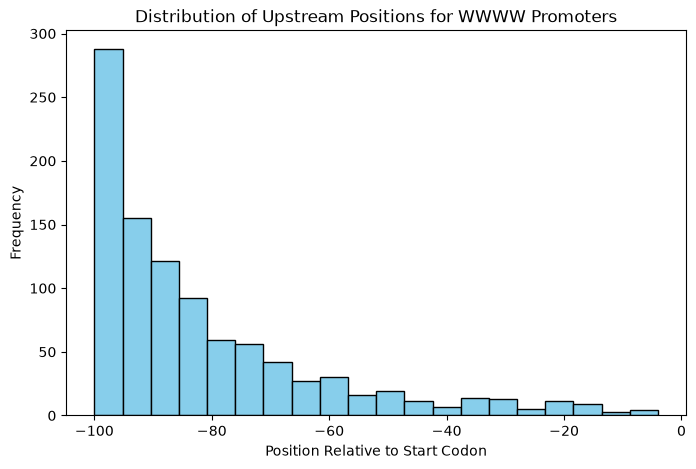

In [ ]:
w_regex = re.compile(r'[AT]{4}')
upstream_positions = []

for seq in sequences:
    upstream_seq = seq[:100] # Restrict to upstream region
    match = w_regex.search(upstream_seq)
    
    if match:
        # Calculate position relative to the start codon 
        relative_pos = match.start() - 100 
        upstream_positions.append(relative_pos)

# percent_promoters = (len(upstream_positions) / len(sequences)) * 100
# print(f"1. Percentage of genes with WWWW promoters: {percent_promoters:.2f}%")


num_promoters = len(upstream_positions)
total_genes = len(sequences)
percent_promoters = (num_promoters / total_genes) * 100
print(f"1. Percentage of genes with WWWW promoters: {num_promoters}/{total_genes} * 100 = {percent_promoters:.2f}%")

plt.figure(figsize=(8, 5))
plt.hist(upstream_positions, bins=20, color='skyblue', edgecolor='black')
plt.title('Distribution of Upstream Positions for WWWW Promoters')
plt.xlabel('Position Relative to Start Codon')
plt.ylabel('Frequency')
plt.show()

## Question 02

2. Maximum consecutive Ws found: 30


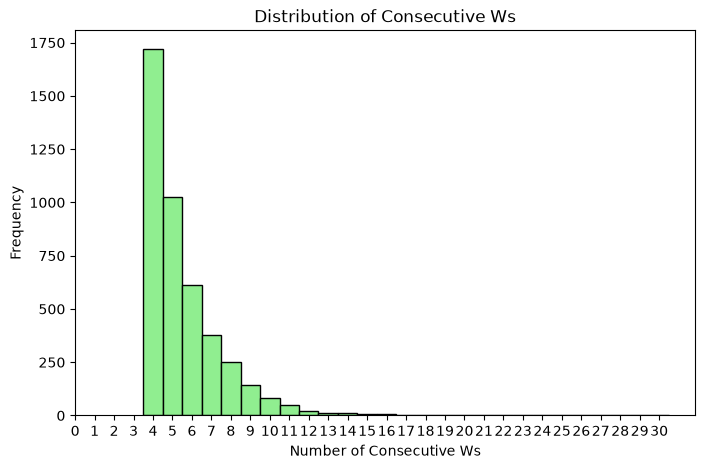

In [ ]:
w_block_regex = re.compile(r'[AT]{4,}')
consecutive_w_counts = []

for seq in sequences:
    upstream_seq = seq[:100]
    matches = w_block_regex.findall(upstream_seq)
    for match in matches:
        consecutive_w_counts.append(len(match))

max_w = max(consecutive_w_counts)
print(f"2. Maximum consecutive Ws found: {max_w}")

plt.figure(figsize=(8, 5))
plt.hist(consecutive_w_counts, bins=np.arange(3.5, max_w + 1.5, 1), 
         color='lightgreen', edgecolor='black')

plt.title('Distribution of Consecutive Ws')
plt.xlabel('Number of Consecutive Ws')
plt.ylabel('Frequency')
plt.xlim(left=0)
plt.xticks(range(0, max_w + 1))

plt.show()

## Question 03

In [6]:
six_mers = []

for seq in sequences:
    upstream_seq = seq[:100]
    match = w_regex.search(upstream_seq)
    if match:
        start_idx = match.start()
        # Grab exactly 6 bases regardless of C/G content
        if start_idx + 6 <= len(seq): 
            six_mers.append(seq[start_idx:start_idx+6])

# Build the PPM
ppm = pd.DataFrame(0.0, index=['A', 'C', 'G', 'T'], columns=range(6))
for kmer in six_mers:
    for i, nuc in enumerate(kmer):
        if nuc in ppm.index:
            ppm.loc[nuc, i] += 1

ppm = ppm / len(six_mers)

print("3. Position Probability Matrix (PPM):")
print(ppm.round(3))

3. Position Probability Matrix (PPM):
       0      1      2      3      4      5
A  0.516  0.478  0.531  0.519  0.262  0.254
C  0.000  0.000  0.000  0.000  0.219  0.252
G  0.000  0.000  0.000  0.000  0.208  0.237
T  0.484  0.522  0.469  0.481  0.312  0.258


#### To create the weblogo

In [7]:
# Generate FASTA format text file for WebLogo
with open("weblogo_sequences.txt", "w") as f:
    for i, kmer in enumerate(six_mers):
        f.write(f">seq_{i}\n{kmer}\n")

print("File 'weblogo_sequences.txt' generated successfully.")

File 'weblogo_sequences.txt' generated successfully.


## Question 4 & 5

File 'aligned_weblogo_sequences.txt' generated successfully.


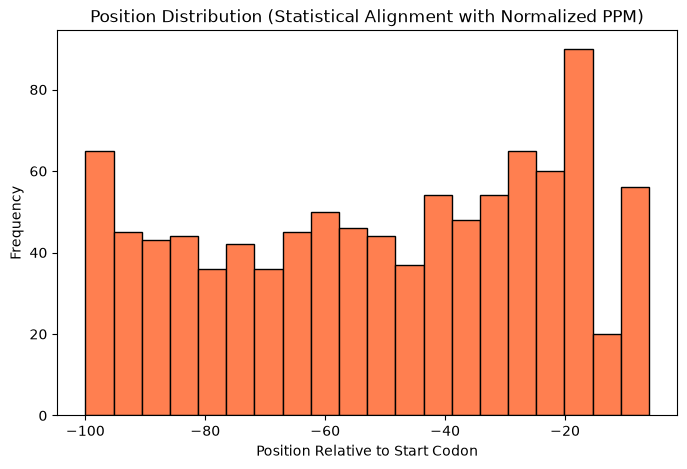

5. Results Comparison:
---------------------------------------------
WWWW Local Search Detection Rate:  98.20%
Statistical Alignment Detection Rate: 98.00%
WWWW Local Search Mean Position:   -81.87
Statistical Alignment Mean Position:  -51.04


In [ ]:
# 1. Define your k value
k = 0.001 

# 2. Normalize the PPM
normalized_ppm = ppm.copy()
for col in normalized_ppm.columns:
    zero_mask = normalized_ppm[col] == 0
    num_zeros = zero_mask.sum()
    if num_zeros > 0:
        normalized_ppm.loc[~zero_mask, col] *= (1 - (num_zeros * k))
        normalized_ppm.loc[zero_mask, col] = k

# 3. Convert the normalized PPM to PWM
pwm = np.log2(normalized_ppm / 0.25)

# Initialize the lists
statistical_positions = []
best_aligned_kmers = [] 

# 4. Statistical Alignment Loop
for seq in sequences:
    upstream_seq = seq[:100]
    best_score = -np.inf
    best_pos = None
    best_kmer = None 
    
    # Score every 6-mer window
    for i in range(len(upstream_seq) - 5):
        kmer = upstream_seq[i:i+6]
        score = 0
        for j, nuc in enumerate(kmer):
            if nuc in pwm.index:
                score += pwm.loc[nuc, j]
        
        if score > best_score:
            best_score = score
            best_pos = i
            best_kmer = kmer 
            
    if best_score > 0:
        statistical_positions.append(best_pos - 100)
        best_aligned_kmers.append(best_kmer) 

# 5. Generate WebLogo File
with open("aligned_weblogo_sequences.txt", "w") as f:
    for i, kmer in enumerate(best_aligned_kmers):
        f.write(f">seq_{i}\n{kmer}\n")

print("File 'aligned_weblogo_sequences.txt' generated successfully.")

# 6. Plotting
percent_stat = (len(statistical_positions) / len(sequences)) * 100
plt.figure(figsize=(8, 5))
plt.hist(statistical_positions, bins=20, color='coral', edgecolor='black')
plt.title('Position Distribution (Statistical Alignment with Normalized PPM)')
plt.xlabel('Position Relative to Start Codon')
plt.ylabel('Frequency')
plt.show()


#Output
print("5. Results Comparison:")
print("-" * 45)
print(f"WWWW Local Search Detection Rate:  {percent_promoters:.2f}%")
print(f"Statistical Alignment Detection Rate: {percent_stat:.2f}%")
print(f"WWWW Local Search Mean Position:   {np.mean(upstream_positions):.2f}")
print(f"Statistical Alignment Mean Position:  {np.mean(statistical_positions):.2f}")

In [10]:
print("Normalized PPM (with k = 0.001 for zero entries):")
print(normalized_ppm.round(4))


Normalized PPM (with k = 0.001 for zero entries):
        0       1       2       3       4       5
A  0.5153  0.4766  0.5295  0.5183  0.2617  0.2536
C  0.0010  0.0010  0.0010  0.0010  0.2189  0.2515
G  0.0010  0.0010  0.0010  0.0010  0.2077  0.2373
T  0.4827  0.5214  0.4685  0.4797  0.3116  0.2576


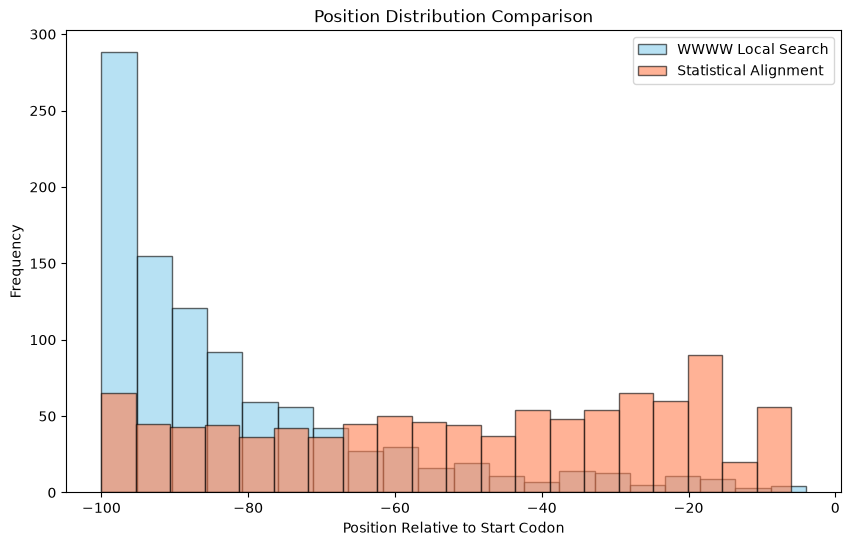

In [12]:
plt.figure(figsize=(10, 6))
plt.hist(upstream_positions, bins=20, color='skyblue', edgecolor='black', alpha=0.6, label='WWWW Local Search')
plt.hist(statistical_positions, bins=20, color='coral', edgecolor='black', alpha=0.6, label='Statistical Alignment')
plt.title('Position Distribution Comparison')
plt.xlabel('Position Relative to Start Codon')
plt.ylabel('Frequency')
plt.legend()
plt.show()
